## ISOM4030 Lab 6.1 - Sequential API, Functional API, and Model Subclassing (Optional) in Tensorflow

### TensorFlow 2 quickstart
Originally developed by Google Brain, TensorFlow is an open source library which provides a variety of functions and classes used to conduct machine learning algorithm.

TensorFlow has various benefits, including
- Python API
- Portability: can be distributed on multiple CPUs, GPUs, or TPUs as well as on mobile devices
- Flexibility: can run on different devices e.g. Raspberry Pi, Android, iOS, Windows, Linux
- Visualization: visualize the training process via TensorBoard
- Checkpoints: manage trained models
- Auto-differentiation
- Large community

Later on, we will try to:
- Load dataset via `tf.keras.datasets`
- Build model via high-level *Sequential API*
- Build model via more flexible *Functional API*
- Build model via fully-customizable *Model Subclassing* (optional)


TensorFlow is an end-to-end open source platform for machine learning. It has a comprehensive, flexible ecosystem of tools, libraries and community resources that lets researchers push the state-of-the-art in ML and developers easily build and deploy ML powered applications. TensorFlow has several benefits:
1. Easy model building
2. Robust ML production anywhere
3. Powerful experimentation for research

An **API** (Application Programming Interface) is a set of rules and protocols that allows different software applications to communicate with each other. It acts like a bridge between systems, enabling them to request and exchange data or services.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

### Load dataset via tf.keras.dataset
Currently, [`tf.keras.dataset`](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/datasets) supports 7 datasets. Including:
- `mnist` module: MNIST handwritten digits dataset.
- `cifar10` module: CIFAR10 small images classification dataset.
- `cifar100` module: CIFAR100 small images classification dataset.
- `fashion_mnist` module: Fashion-MNIST dataset.
- `imdb` module: IMDB sentiment classification dataset.
- `boston_housing` module: Boston housing price regression dataset.
- `reuters` module: Reuters topic classification dataset.

In this lab, we will use [MNIST dataset](http://yann.lecun.com/exdb/mnist/) to demo how to build a neural network. MNIST contains 70,000 images of hand-written digits, 60,000 for training while 10,000 for testing, each $28×28$ pixels, in greyscale with pixel-values from 0 to 255.

In [2]:
# Helper function
def show_images(image, num_row=2, num_col=5):
    # plot images
    fig, axes = plt.subplots(num_row, num_col, figsize=(1.5*num_col,2*num_row))
    for i in range(num_row*num_col):
        ax = axes[i//num_col, i%num_col]
        ax.imshow(image[i], cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

Load and prepare the MNIST dataset. Convert the samples from integers to floating-point numbers:

In [3]:
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Training data: (60000, 28, 28)
Test data: (10000, 28, 28)


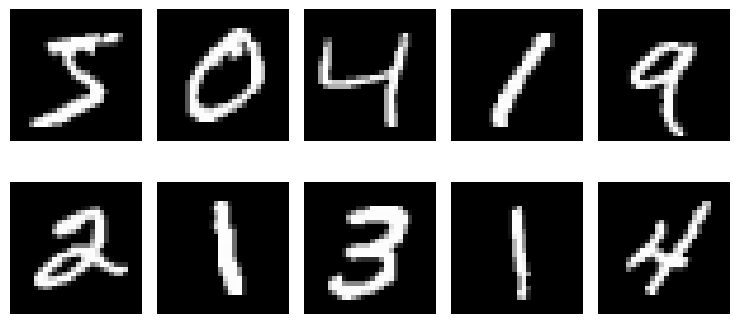

In [4]:
print("Training data: {}".format(x_train.shape))
print("Test data: {}".format(x_test.shape))
show_images(x_train)

### Build model via Sequential API
### When to use?
A `Sequential API` is the simplest way to build a model, which is appropriate for **a plain stack of layers** where each layer has **exactly one input tensor and one output tensor**.

Build the [`tf.keras.Sequential`](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential) model by stacking layers. Choose an optimizer and loss function for training:

In [5]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


For each example the model returns a vector of "logits" or "log-odds" scores, one for each class.

In [6]:
predictions = model(x_train[:1]).numpy()
predictions

array([[-0.28713298,  0.7890638 , -0.00085481,  0.02205447,  0.6547153 ,
         0.02040666, -0.06369741,  0.25504273,  0.2563102 ,  0.7985722 ]],
      dtype=float32)

The [`tf.nn.softmax`](https://www.tensorflow.org/api_docs/python/tf/nn/softmax) function converts these logits to "probabilities" for each class:

In [7]:
tf.nn.softmax(predictions).numpy()

array([[0.05492804, 0.1611315 , 0.07313465, 0.07482945, 0.1408749 ,
        0.07470624, 0.06868011, 0.0944622 , 0.094582  , 0.16267091]],
      dtype=float32)

<font color="red"> <b>Note</b></font>: It is possible to bake this `tf.nn.softmax` in as the activation function for the last layer of the network. While this can make the model output more directly interpretable, this approach is discouraged as it's impossible to provide an exact and numerically stable loss calculation for all models when using a softmax output.

The [`losses.SparseCategoricalCrossentropy`](https://www.tensorflow.org/api_docs/python/tf/keras/losses/SparseCategoricalCrossentropy) loss takes a vector of logits and a True index and returns a scalar loss for each example (If labels use ***one-hot representation***, we need to use the `CategoricalCrossentropy` loss instead):

In [8]:
# the output layer has no activation (i.e., tf.keras.layers.Dense(10) above). So what it outputs are logits

loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

This loss is equal to the negative log probability of the true class: It is zero if the model is sure of the correct class.

This untrained model gives probabilities close to random (1/10 for each class), so the initial loss should be close to `-tf.log(1/10) ~= 2.3`.

In [9]:
loss_fn(y_train[:1], predictions).numpy()

np.float32(2.5941916)

In [10]:
model.compile(optimizer='adam', loss=loss_fn, metrics=['accuracy'])

The [`Model.summary`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#summary) method prints a string summary of the network, which is quite useful to examining model architecture before training.

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

The [`Model.fit`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit) method adjusts the model parameters to minimize the loss:

In [12]:
model.fit(x_train, y_train, batch_size=32, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8558 - loss: 0.4910
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9549 - loss: 0.1519
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9669 - loss: 0.1084
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9736 - loss: 0.0852
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9777 - loss: 0.0731


The [`Model.evaluate`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#evaluate) method checks the models performance, usually on a "Validation-set" or "Test-set".

In [45]:
model.evaluate(x_test, y_test, verbose=2)

313/313 - 1s - 3ms/step - accuracy: 0.9747 - loss: 0.0860


[0.08603977411985397, 0.9746999740600586]

The image classifier is now trained to ~98% accuracy on this dataset.

In [14]:
# Destroys the current TF graph and creates a new one.
tf.keras.backend.clear_session()

### Build model via Functional API


Not all neural network models are simply sequential. Some may have complex topologies. Some may have multiple inputs and/or multiple outputs. For example, a Wide & Deep neural network (see [paper](https://ai.google/research/pubs/pub45413)) connects all or part of the inputs directly to the output layer. This architecture makes it possible for the neural network to learn both deep patterns (using the deep path) and simple rules (through the short path).


### When to use?
The Keras *Functional API* is a way to create models that are **more flexible** than the `tf.keras.Sequential` API. The functional API can handle models with non-linear topology, shared layers, and even multiple inputs or outputs.

The main idea is that a deep learning model is usually a directed acyclic graph (DAG) of layers. So the functional API is a way to build *graphs of layers*.

Consider the following model:

```
(input: (28, 28)-dimensional vectors)
       ↧
[Flatten]
       ↧
[Dense (128 units, relu activation)]
       ↧
[Dropout]
       ↧
[Dense (10 units, no activation)]
       ↧
(output: logits for a probability distribution over 10 classes)
```

This is a basic graph with four layers. To build this model using the functional API, start by creating an input node:

In [51]:
inputs = tf.keras.Input(shape=(28, 28))

The shape of the data is set as a 784-dimensional vector. The batch size is always omitted since only the shape of each sample is specified. The `inputs` that is returned contains information about the shape and `dtype` of the input data that you feed to your model.

In [52]:
print("Shape:", inputs.shape)
# print("dtype:", inputs.dtype)

Shape: (None, 28, 28)


You create a new node in the graph of layers by calling a layer on this `inputs` object. The "layer call" action is like drawing an arrow from "inputs" to this layer you created. You're "passing" the inputs to the `dense` layer, and you get `x` as the output.

Let's add a few more layers to the graph of layers:

In [53]:
x = tf.keras.layers.Flatten()(inputs)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(10)(x)

At this point, you can create a Model by specifying its inputs and outputs in the graph of layers:

In [54]:
model = tf.keras.Model(inputs=inputs, outputs=outputs, name="mnist_model")
model.summary()

Model: "mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
model.layers

[<InputLayer name=input_layer_3, built=True>,
 <Flatten name=flatten_1, built=True>,
 <Dense name=dense_2, built=True>,
 <Dropout name=dropout_1, built=True>,
 <Dense name=dense_3, built=True>]

In [56]:
model.layers[2].get_weights()    # numpy array

[array([[-0.00827565, -0.06983588,  0.04031179, ...,  0.05556103,
          0.06833317,  0.00948967],
        [ 0.02084733, -0.03534745, -0.07329668, ...,  0.03558479,
         -0.06511524,  0.03117278],
        [-0.06220765, -0.02471771, -0.01215093, ...,  0.02098805,
         -0.05652338,  0.00445864],
        ...,
        [-0.06395388,  0.02258698, -0.07284132, ..., -0.06342912,
         -0.00246409, -0.05973912],
        [-0.02828979,  0.07260632,  0.05468548, ..., -0.06131546,
          0.05115036, -0.07515546],
        [-0.03791142,  0.05195851, -0.0415799 , ..., -0.01589716,
          0.02767322, -0.00670534]], dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.

In [61]:
model.layers[2].weights    # each element is a tensorflow variable object; the first array packs all incoming weights, while the 2nd array packs all bias terms

[<Variable path=dense_2/kernel, shape=(784, 128), dtype=float32, value=[[-0.00827565 -0.06983588  0.04031179 ...  0.05556103  0.06833317
    0.00948967]
  [ 0.02084733 -0.03534745 -0.07329668 ...  0.03558479 -0.06511524
    0.03117278]
  [-0.06220765 -0.02471771 -0.01215093 ...  0.02098805 -0.05652338
    0.00445864]
  ...
  [-0.06395388  0.02258698 -0.07284132 ... -0.06342912 -0.00246409
   -0.05973912]
  [-0.02828979  0.07260632  0.05468548 ... -0.06131546  0.05115036
   -0.07515546]
  [-0.03791142  0.05195851 -0.0415799  ... -0.01589716  0.02767322
   -0.00670534]]>,
 <Variable path=dense_2/bias, shape=(128,), dtype=float32, value=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

In [57]:
len(model.layers[4].get_weights()[1])

10

In [63]:
model.layers[2].weights[0].shape   # 748 x 128 weights ; 128 bias in layers 2

TensorShape([784, 128])

In [64]:
model.layers[4].weights[1].shape    # 128 x 10 weights; 10 bias in layer 4

TensorShape([10])

In [25]:
[layer.name for layer in model.layers if isinstance(layer, tf.keras.layers.Dense)]

['dense', 'dense_1']

In [26]:
[layer.name for layer in model.layers if isinstance(layer, tf.keras.layers.Dropout)]

['dropout']

Training, evaluation, and inference work exactly in the same way for models built using the functional API as for `Sequential` models.

In [28]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy']
             )

history = model.fit(x_train, y_train, batch_size=64, epochs=5, validation_split=0.2)
# 60000 instance in original x_train, 48000 (80%) being trained, 12000 (20%) as validation set
# 48000 / 64 = 750, i.e. number of iteration per each epoch
# means in each epoch, it updates the parameters 750 times

test_scores = model.evaluate(x_test, y_test, verbose=2) # batch_size = 32 by default
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8189 - loss: 0.6196 - val_accuracy: 0.9497 - val_loss: 0.1816
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9440 - loss: 0.1910 - val_accuracy: 0.9620 - val_loss: 0.1307
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9570 - loss: 0.1403 - val_accuracy: 0.9669 - val_loss: 0.1130
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9662 - loss: 0.1151 - val_accuracy: 0.9732 - val_loss: 0.0961
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9703 - loss: 0.0915 - val_accuracy: 0.9741 - val_loss: 0.0884
313/313 - 1s - 2ms/step - accuracy: 0.9743 - loss: 0.0814
Test loss: 0.08143468201160431
Test accuracy: 0.9743000268936157


In [29]:
# Destroys the current TF graph and creates a new one.
tf.keras.backend.clear_session()

In [30]:
# a pre-trained MobileNet V2 model

mobilev2_model = tf.keras.applications.MobileNetV2(input_shape=(160, 160, 3),
                                                   weights='imagenet')          # use the weights learned from ImageNet

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [31]:
#mobilev2_model.summary()

In [32]:
# it has 156 layers
len(mobilev2_model.layers)

156

In [70]:
#mobilev2_model.summary()

Question: how many Dense layers are used

In [67]:
[layer.name for layer in mobilev2_model.layers if isinstance(layer, tf.keras.layers.Dense)]

['predictions']

### Build model via Model Subclassing (optional)
### When to use?
The final method to implement a model architecture is called *Model Subclassing*. Model subclassing is **fully-customizable** and enables you to **implement your own custom forward-pass of the model**. However, this flexibility and customization comes at a cost — **model subclassing is way harder to utilize than the Sequential API or Functional API**.

So, if the model subclassing method is so hard to use, why bother utilizing it all?

Exotic architectures or custom layer/model implementations, **especially those utilized by researchers**, can be extremely challenging, if not impossible, to implement using the standard Sequential or Functional APIs. Instead, researchers wish to have control over every nuance of the network and training process — and that’s exactly what model subclassing provides them.

Use [`tf.data`](https://www.tensorflow.org/api_docs/python/tf/data) to batch and shuffle the dataset:

In [34]:
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(10000).batch(32)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(32)

Build the `tf.keras` model using the Keras [model subclassing API](https://www.tensorflow.org/guide/keras/custom_layers_and_models):

In [35]:
class MyModel(tf.keras.Model):
    def __init__(self):
        super(MyModel, self).__init__()
        self.flatten = tf.keras.layers.Flatten()
        self.dropout = tf.keras.layers.Dropout(0.2)
        self.d1 = tf.keras.layers.Dense(128, activation='relu')
        self.d2 = tf.keras.layers.Dense(10)

    def call(self, x):
        x = self.flatten(x)
        x = self.d1(x)
        x = self.dropout(x)
        return self.d2(x)

In [36]:
# Create an instance of the model
model = MyModel()

# To create a model summary, we need to tell the model how many input features there are
model.build(input_shape=(None, 28, 28))
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'my_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "my_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Choose an optimizer and loss function for training.

In [37]:
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer = tf.keras.optimizers.Adam()

In [38]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy']
             )

history = model.fit(x_train, y_train, batch_size=64, epochs=5, validation_split=0.2)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8466 - loss: 0.5538 - val_accuracy: 0.9503 - val_loss: 0.1779
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9530 - loss: 0.1617 - val_accuracy: 0.9613 - val_loss: 0.1344
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9679 - loss: 0.1111 - val_accuracy: 0.9659 - val_loss: 0.1131
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9765 - loss: 0.0829 - val_accuracy: 0.9695 - val_loss: 0.1028
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9820 - loss: 0.0628 - val_accuracy: 0.9725 - val_loss: 0.0894


### Sequential API, Functional API, and Model Subclassing


<img src="https://raw.githubusercontent.com/justinjiajia/ml/master/labs/10_TensorFlow101/figs/tf_model.png" width="500"/>


Should you use the Keras functional API to create a new model, or just subclass the Model class directly? In general, the functional API is higher-level, easier and safer, and has a number of features that subclassed models do not support. However, model subclassing provides greater flexibility when building models that are not easily expressible as directed acyclic graphs of layers. For example, you could not implement a Tree-RNN with the functional API and would have to subclass Model directly.

Choosing between the functional API or Model subclassing isn't a binary decision that restricts you into one category of models. All models in the `tf.keras` API can interact with each other, whether they're `Sequential` models, functional models, or subclassed models that are written from scratch.

For an in-depth look at the differences between the functional API and model subclassing, read [What are Symbolic and Imperative APIs in TensorFlow 2.0?](https://blog.tensorflow.org/2019/01/what-are-symbolic-and-imperative-apis.html).

#### <font color='steelblue' > Exercise </font>

Build NN model with Sequential API, Functional API & Model Subclassing. The model Layer Architecture is as below:


**Input Shape**: The input shape of the model is expected to be [28, 28], representing 2D images with dimensions 28x28 pixels.

**Flatten layer**: It flattens the input images into a 1D array.

**Dense layer with 50 units and ReLU activation**: A fully connected layer with 50 units and applies the ReLU activation function.

**Dense layer with 10 units and ReLU activation**: Another fully connected layer with 10 units and ReLU activation.

**Output layer**: This is the output layer without any activation function specified.

**Loss Function**: The model uses SparseCategoricalCrossentropy as the loss function, for multi-class classification problems. Also, assume the labels are integers.

**Optimizer**: The model is compiled with the SGD optimizer with a learning rate of 0.001.

**Metrics**: The model uses accuracy as the evaluation metric during training.

The training is performed for 25 epochs with a batch size of 32. The training data is provided as x_train and y_train, while the validation data is specified as x_test and y_test.

In [39]:
# Model built with Sequential API

# Step 1: Build the model (Define the layers and stack them into a network in order)
model_ex_seq = tf.keras.models.Sequential([tf.keras.layers.Flatten(input_shape=[28, 28], name="flattened_input"),
                                          tf.keras.layers.Dense(50, activation='relu', name="fully_connected_1"),
                                          tf.keras.layers.Dense(10, activation='relu', name="fully_connected_2"),
                                          tf.keras.layers.Dense(10, name="output")],       # add softmax after compile stage
                                          name="my_mnist_model")

# Print a summary of the network to examine model architecture
print(model_ex_seq.summary())

# Step 2: Compile the model (Specify the loss function and optimizer to use)
model_ex_seq.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

# Step 3: Train the model (Specify batch size and number of epochs)
model_output_1 = model_ex_seq.fit(x_train, y_train, batch_size=32, epochs=25, validation_data=(x_test, y_test))

Model: "my_mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flattened_input (Flatten)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_1 (Dense)       │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_2 (Dense)       │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,870 (155.74 KB)

 Trainable params: 39,870 (155.74 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.1882 - loss: 2.1774 - val_accuracy: 0.4320 - val_loss: 1.7673
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.4947 - loss: 1.6509 - val_accuracy: 0.6849 - val_loss: 1.2128
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7202 - loss: 1.1141 - val_accuracy: 0.8181 - val_loss: 0.7971
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8195 - loss: 0.7586 - val_accuracy: 0.8533 - val_loss: 0.5994
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8541 - loss: 0.5904 - val_accuracy: 0.8728 - val_loss: 0.5039
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8724 - loss: 0.4991 - val_accuracy: 0.8818 - val_loss: 0.4498
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8785 - loss: 0.4543 - val_accuracy: 0.8889 - val_loss: 0.4157
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8837 - loss: 0.42

In [40]:
# Model built with Functional API

# Step 1: Define the input layer
inputs = tf.keras.Input(shape=(28, 28))

# Step 2: Build the model architecture by connecting layers
flatten = tf.keras.layers.Flatten(name="flattened_input")(inputs)
dense1 = tf.keras.layers.Dense(50, activation='relu', name="fully_connected_1")(flatten)
dense2 = tf.keras.layers.Dense(10, activation='relu', name="fully_connected_2")(dense1)
output = tf.keras.layers.Dense(10, name="output")(dense2)

# Step 3: Create the model by specifying inputs and outputs
model_ex_fun = tf.keras.Model(inputs=inputs, outputs=output, name="my_mnist_model")

# Print a summary of the network to examine model architecture
print(model_ex_fun.summary())

# Step 4: Compile the model (Specify the loss function and optimizer to use)
model_ex_fun.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

# Step 5: Train the model (Specify batch size and number of epochs)
model_output_2 = model_ex_fun.fit(x_train, y_train, batch_size=32, epochs=25, validation_data=(x_test, y_test))

Model: "my_mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flattened_input (Flatten)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_1 (Dense)       │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_2 (Dense)       │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,870 (155.74 KB)

 Trainable params: 39,870 (155.74 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.1908 - loss: 2.2213 - val_accuracy: 0.4154 - val_loss: 1.8588
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4940 - loss: 1.7286 - val_accuracy: 0.6252 - val_loss: 1.3447
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6506 - loss: 1.2410 - val_accuracy: 0.7419 - val_loss: 0.9497
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7550 - loss: 0.8912 - val_accuracy: 0.7998 - val_loss: 0.7150
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8017 - loss: 0.6953 - val_accuracy: 0.8327 - val_loss: 0.5946
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8271 - loss: 0.5958 - val_accuracy: 0.8496 - val_loss: 0.5273
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8496 - loss: 0.5253 - val_accuracy: 0.8621 - val_loss: 0.4845
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8559 - loss: 0.49

In [41]:
# Model built with Subclassing

# Step 1: Define the custom model class
class MyMNISTModel(tf.keras.Model):
    def __init__(self):
        super(MyMNISTModel, self).__init__()

        # Define the layers
        self.flatten = tf.keras.layers.Flatten(name="flattened_input")
        self.dense1 = tf.keras.layers.Dense(50, activation='relu', name="fully_connected_1")
        self.dense2 = tf.keras.layers.Dense(10, activation='relu', name="fully_connected_2")
        self.output_layer = tf.keras.layers.Dense(10, name="output")

    def call(self, inputs):
        # Define the forward pass
        x = self.flatten(inputs)
        x = self.dense1(x)
        x = self.dense2(x)
        output = self.output_layer(x)
        return output

# Step 2: Create an instance of the model
model_ex_sub = MyMNISTModel()
model_ex_sub.build(input_shape=(None, 28, 28))
model_ex_sub.summary()

# Step 3: Compile the model (Specify the loss function and optimizer to use)
model_ex_sub.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

# Step 4: Train the model (Specify batch size and number of epochs)
model_output_3 = model_ex_sub.fit(x_train, y_train, batch_size=32, epochs=25, validation_data=(x_test, y_test))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'my_mnist_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "my_mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flattened_input (Flatten)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_1 (Dense)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fully_connected_2 (Dense)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.1808 - loss: 2.2004 - val_accuracy: 0.4792 - val_loss: 1.8239
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5277 - loss: 1.6827 - val_accuracy: 0.7143 - val_loss: 1.1854
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7154 - loss: 1.1107 - val_accuracy: 0.7845 - val_loss: 0.8230
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.7804 - loss: 0.8090 - val_accuracy: 0.8185 - val_loss: 0.6588
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8124 - loss: 0.6621 - val_accuracy: 0.8404 - val_loss: 0.5702
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8341 - loss: 0.5755 - val_accuracy: 0.8538 - val_loss: 0.5139
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8498 - loss: 0.5219 - val_accuracy: 0.8641 - val_loss: 0.4740
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8601 - loss: 0.4852 -

# Reference
- [TensorFlow](https://www.tensorflow.org/)
- [3 ways to create a Keras model with TensorFlow 2.0](https://www.pyimagesearch.com/2019/10/28/3-ways-to-create-a-keras-model-with-tensorflow-2-0-sequential-functional-and-model-subclassing/)